<a href="https://colab.research.google.com/github/carlavilla/DataManagement/blob/main/Flooding_and_Housing_NJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time, os, sys, re
import zipfile, json, datetime, string
import numpy as np
from statistics import *

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import pandas_datareader as pdr
from pandas_datareader import wb
from pandas.io.formats.style import Styler

import missingno as msno

from google.colab import files
from google.colab import data_table
data_table.enable_dataframe_formatter()
data_table.max_columns = 50
#!and may have to click at top right spreadsheet icon

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

#ALICE Data

Uses data from the ACS to report the number of households living in poverty as well as those in financial hardship. ALICE scores take into consideration household costs (e.g. housing, food, transportation, healthcare, technology) based on the location. Households under the ALICE threshold do not have enough income to afford their basic needs. </br>

**Variables of interest:** Per county, total number of households, households in poverty, ALICE households, ALICE income thresholds for households under 65, ALICE income thresholds for households over 65.</br>

**Timeframe available:** 2010, 2012, 2014, 2016, 2018, 2019, 2021, 2022, 2023, 2024. </br>

**Areas in dataset:** Counties in New Jersey. </br>

*Thresholds are for the average household, calculated by dividing the total number of households in each county by the population in that age group in that county.

**Source:** [United for Alice 2026 Report](https://www.unitedforalice.org/county-reports/new-jersey)

In [ ]:
! wget -q -O ALICE_NJ.xlsx https://raw.githubusercontent.com/carlavilla/DataManagement/main/ALICE_NJ.xlsx
alice=pd.read_excel('ALICE_NJ.xlsx', sheet_name= "County")
alice.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   State                                   210 non-null    object
 1   Year                                    210 non-null    int64 
 2   GEO.id2                                 210 non-null    int64 
 3   GEO.display_label                       210 non-null    object
 4   County                                  210 non-null    object
 5   State Abbr                              210 non-null    object
 6   Households                              210 non-null    int64 
 7   Poverty Households                      210 non-null    int64 
 8   ALICE Households                        210 non-null    int64 
 9   Above ALICE Households                  210 non-null    int64 
 10  ALICE Threshold - HH under 65           210 non-null    int64 
 11  ALICE 

In [ ]:
alice.head()

,State,Year,GEO.id2,GEO.display_label,County,State Abbr,Households,Poverty Households,ALICE Households,Above ALICE Households,ALICE Threshold - HH under 65,ALICE Threshold - HH 65 years and over,Source: American Community Survey
0,New Jersey,2010,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100096,12106,30689,57301,45000,40000,1-Year
1,New Jersey,2012,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100065,13381,32214,54470,50000,40000,1-Year
2,New Jersey,2014,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,101937,14493,30462,56982,50000,45000,1-Year
3,New Jersey,2016,34001,"Atlantic County, New Jersey",Atlantic,NJ,96777,13436,32971,50370,60000,45000,1-Year
4,New Jersey,2018,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,96981,12343,31914,52724,60000,50000,1-Year


In [ ]:
alice = alice.drop(columns=["State", "GEO.display_label", "GEO.id2", "State Abbr", "Source: American Community Survey "], errors='ignore')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   Year                                    210 non-null    int64 
 1   County                                  210 non-null    object
 2   Households                              210 non-null    int64 
 3   Poverty Households                      210 non-null    int64 
 4   ALICE Households                        210 non-null    int64 
 5   Above ALICE Households                  210 non-null    int64 
 6   ALICE Threshold - HH under 65           210 non-null    int64 
 7   ALICE Threshold - HH 65 years and over  210 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 13.3+ KB


In [ ]:
alice= alice.rename(columns={'Households': 'HH',
                             'Poverty Households': 'povertyHH',
                             'ALICE Households': 'aliceHH',
                             'Above ALICE Households': '>aliceHH',
                             'ALICE Threshold - HH under 65': 'alice$65under',
                             'ALICE Threshold - HH 65 years and over': 'alice$65over'})

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Year           210 non-null    int64 
 1   County         210 non-null    object
 2   HH             210 non-null    int64 
 3   povertyHH      210 non-null    int64 
 4   aliceHH        210 non-null    int64 
 5   >aliceHH       210 non-null    int64 
 6   alice$65under  210 non-null    int64 
 7   alice$65over   210 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 13.3+ KB


<Axes: >

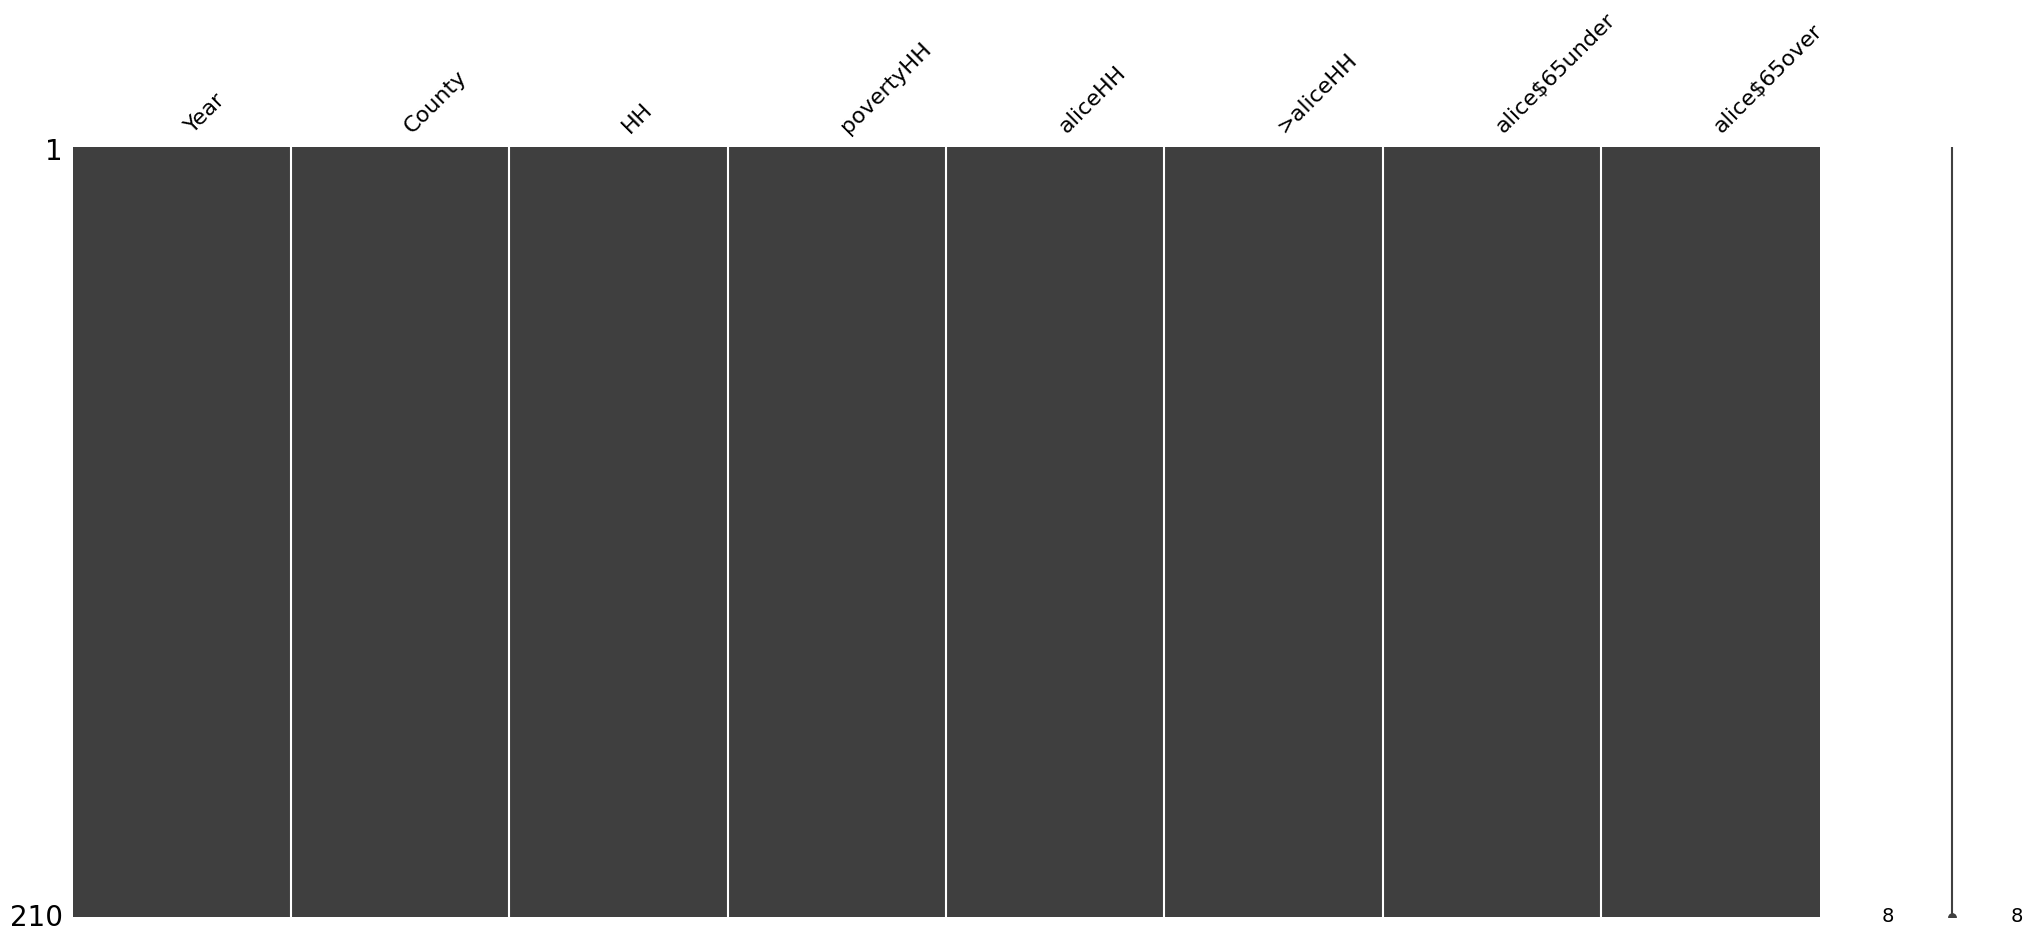

In [ ]:
msno.matrix(alice)

#ACS Data
Data on population and income for every county in New Jersey. 1-year estimates except for 2020 (obtained from 5-year estimates)

**Variables of Interest:** County, total population, total housing units, median income.

**Timeframe available:** 2010 through 2025.

**Areas in dataset:** Counties in New Jersey.

**Source:** [American Community Survey](https://www.census.gov/programs-surveys/acs/data.html)

In [95]:
! wget -q -O ACS_pop.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_pop.zip
zip_ref = zipfile.ZipFile('ACS_pop.zip', 'r'); zip_ref.extractall(); zip_ref.close()
#https://raw.githubusercontent.com/carlavilla/DataManagement/main/ACS_pop.zip
with zipfile.ZipFile("ACS_pop.zip", 'r') as zip_ref:
    # Get a list of all file paths inside the ZIP
    pop_list = zip_ref.namelist()
    pop_list

['ACSDP1Y2025.DP05-Data.csv',
 'ACSDP1Y2025.DP05-Column-Metadata.csv',
 'ACSDP1Y2025.DP05-Table-Notes.txt',
 'ACSDP1Y2024.DP05-Data.csv',
 'ACSDP1Y2024.DP05-Column-Metadata.csv',
 'ACSDP1Y2024.DP05-Table-Notes.txt',
 'ACSDP1Y2023.DP05-Data.csv',
 'ACSDP1Y2023.DP05-Column-Metadata.csv',
 'ACSDP1Y2023.DP05-Table-Notes.txt',
 'ACSDP1Y2022.DP05-Data.csv',
 'ACSDP1Y2022.DP05-Column-Metadata.csv',
 'ACSDP1Y2022.DP05-Table-Notes.txt',
 'ACSDP1Y2021.DP05-Data.csv',
 'ACSDP1Y2021.DP05-Column-Metadata.csv',
 'ACSDP1Y2021.DP05-Table-Notes.txt',
 'ACSDP1Y2019.DP05-Data.csv',
 'ACSDP1Y2019.DP05-Column-Metadata.csv',
 'ACSDP1Y2019.DP05-Table-Notes.txt',
 'ACSDP1Y2018.DP05-Data.csv',
 'ACSDP1Y2018.DP05-Column-Metadata.csv',
 'ACSDP1Y2018.DP05-Table-Notes.txt',
 'ACSDP1Y2017.DP05-Data.csv',
 'ACSDP1Y2017.DP05-Column-Metadata.csv',
 'ACSDP1Y2017.DP05-Table-Notes.txt',
 'ACSDP1Y2016.DP05-Data.csv',
 'ACSDP1Y2016.DP05-Column-Metadata.csv',
 'ACSDP1Y2016.DP05-Table-Notes.txt',
 'ACSDP1Y2015.DP05-Data.csv'

In [96]:
acspop2010=pd.read_csv('ACSDP1Y2010.DP05-Data.csv')
acspop2010= acspop2010[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2010['Year'] = 2010
acspop10= acspop2010.drop([0])
acspop10= acspop10.rename(columns={'DP05_0081E': 'H_units'})

acspop2012=pd.read_csv('ACSDP1Y2012.DP05-Data.csv')
acspop2012= acspop2012[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2012['Year'] = 2012
acspop12= acspop2012.drop([0])
acspop12= acspop12.rename(columns={'DP05_0081E': 'H_units'})

acspop2014=pd.read_csv('ACSDP1Y2014.DP05-Data.csv')
acspop2014= acspop2014[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2014['Year'] = 2014
acspop14= acspop2014.drop([0])
acspop14= acspop14.rename(columns={'DP05_0081E': 'H_units'})

acspop2016=pd.read_csv('ACSDP1Y2016.DP05-Data.csv')
acspop2016= acspop2016[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2016['Year'] = 2016
acspop16= acspop2016.drop([0])
acspop16= acspop16.rename(columns={'DP05_0081E': 'H_units'})

acspop2018=pd.read_csv('ACSDP1Y2018.DP05-Data.csv')
acspop2018= acspop2018[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2018['Year'] = 2018
acspop18= acspop2018.drop([0])
acspop18= acspop18.rename(columns={'DP05_0086E': 'H_units'})

acspop2019=pd.read_csv('ACSDP1Y2019.DP05-Data.csv')
acspop2019= acspop2019[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2019['Year'] = 2019
acspop19= acspop2019.drop([0])
acspop19= acspop19.rename(columns={'DP05_0086E': 'H_units'})

acspop2021=pd.read_csv('ACSDP1Y2021.DP05-Data.csv')
acspop2021= acspop2021[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2021['Year'] = 2021
acspop21= acspop2021.drop([0])
acspop21= acspop21.rename(columns={'DP05_0086E': 'H_units'})

acspop2022=pd.read_csv('ACSDP1Y2022.DP05-Data.csv')
acspop2022= acspop2022[['NAME', 'DP05_0001E', 'DP05_0088E']]
acspop2022['Year'] = 2022
acspop22= acspop2022.drop([0])
acspop22= acspop22.rename(columns={'DP05_0088E': 'H_units'})

acspop2023=pd.read_csv('ACSDP1Y2023.DP05-Data.csv')
acspop2023= acspop2023[['NAME', 'DP05_0001E', 'DP05_0091E']]
acspop2023['Year'] = 2023
acspop23= acspop2023.drop([0])
acspop23= acspop23.rename(columns={'DP05_0091E': 'H_units'})

acspop2024=pd.read_csv('ACSDP1Y2024.DP05-Data.csv')
acspop2024= acspop2024[['NAME', 'DP05_0001E', 'DP05_0105E']]
acspop2024['Year'] = 2024
acspop24= acspop2024.drop([0])
acspop24= acspop24.rename(columns={'DP05_0105E': 'H_units'})

In [116]:
acspop= pd.concat([acspop10, acspop12, acspop14, acspop16, acspop18, acspop19, acspop21, acspop22, acspop23, acspop24])
acspop.rename(columns={'NAME': 'County',
                       'DP05_0001E': "Totalpop"},
              inplace=True)
acspop['County'] = acspop['County'].str.replace(' County, New Jersey', '')
acspop= acspop.reset_index(drop=True)
acspop.head(3)

,County,Totalpop,H_units,Year
0,Atlantic,274685,126723,2010
1,Bergen,906541,352412,2010
2,Burlington,449149,175728,2010


<Axes: >

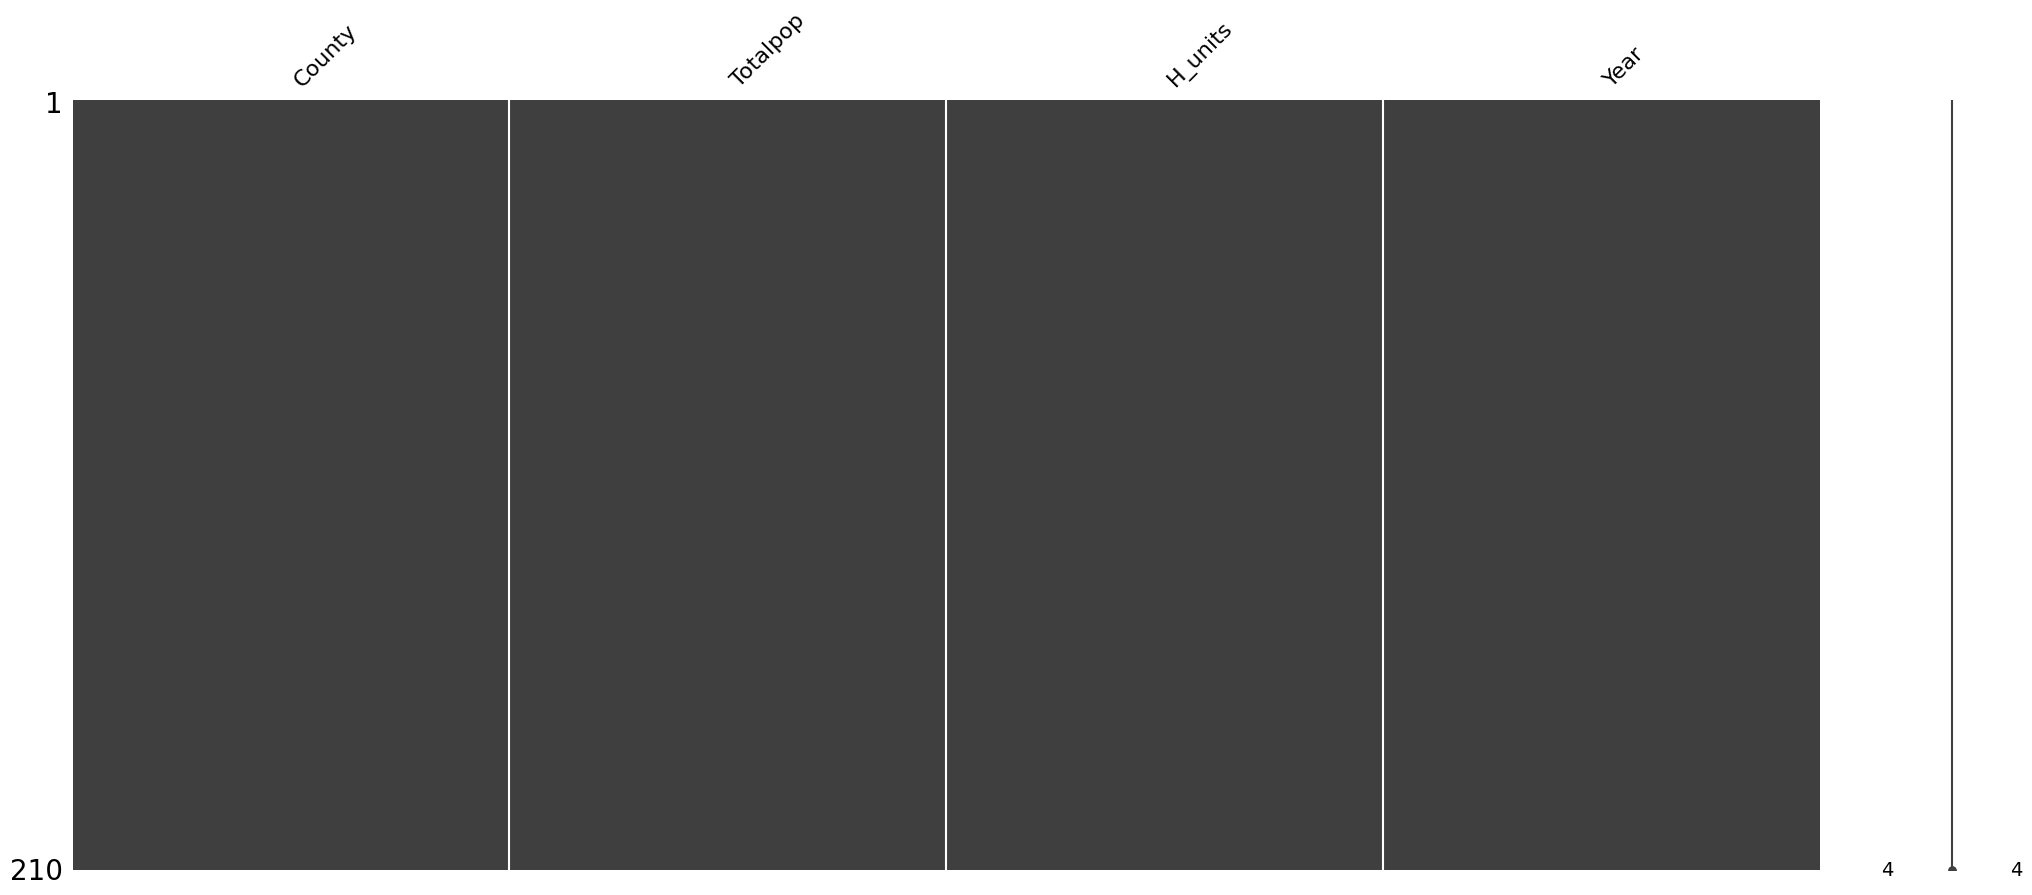

In [99]:
msno.matrix(acspop)

In [100]:
! wget -q -O ACS_income.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_income.zip
zip_ref = zipfile.ZipFile('ACS_income.zip', 'r'); zip_ref.extractall(); zip_ref.close()
with zipfile.ZipFile("ACS_income.zip", 'r') as zip_ref:
    income_list = zip_ref.namelist()
    income_list

['ACSST1Y2025.S1901-Data.csv',
 'ACSST1Y2025.S1901-Column-Metadata.csv',
 'ACSST1Y2025.S1901-Table-Notes.txt',
 'ACSST1Y2024.S1901-Data.csv',
 'ACSST1Y2024.S1901-Column-Metadata.csv',
 'ACSST1Y2024.S1901-Table-Notes.txt',
 'ACSST1Y2023.S1901-Data.csv',
 'ACSST1Y2023.S1901-Column-Metadata.csv',
 'ACSST1Y2023.S1901-Table-Notes.txt',
 'ACSST1Y2022.S1901-Data.csv',
 'ACSST1Y2022.S1901-Column-Metadata.csv',
 'ACSST1Y2022.S1901-Table-Notes.txt',
 'ACSST1Y2021.S1901-Data.csv',
 'ACSST1Y2021.S1901-Column-Metadata.csv',
 'ACSST1Y2021.S1901-Table-Notes.txt',
 'ACSST1Y2019.S1901-Data.csv',
 'ACSST1Y2019.S1901-Column-Metadata.csv',
 'ACSST1Y2019.S1901-Table-Notes.txt',
 'ACSST1Y2018.S1901-Data.csv',
 'ACSST1Y2018.S1901-Column-Metadata.csv',
 'ACSST1Y2018.S1901-Table-Notes.txt',
 'ACSST1Y2017.S1901-Data.csv',
 'ACSST1Y2017.S1901-Column-Metadata.csv',
 'ACSST1Y2017.S1901-Table-Notes.txt',
 'ACSST1Y2016.S1901-Data.csv',
 'ACSST1Y2016.S1901-Column-Metadata.csv',
 'ACSST1Y2016.S1901-Table-Notes.txt',
 

In [108]:
acsinc2010=pd.read_csv('ACSST1Y2010.S1901-Data.csv')
acsinc2010= acsinc2010[['NAME', 'S1901_C01_012E']]
acsinc2010['Year'] = 2010
acsinc10= acsinc2010.drop([0])
acsinc10= acsinc10.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2012=pd.read_csv('ACSST1Y2012.S1901-Data.csv')
acsinc2012= acsinc2012[['NAME', 'S1901_C01_012E']]
acsinc2012['Year'] = 2012
acsinc12= acsinc2012.drop([0])
acsinc12= acsinc12.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2014=pd.read_csv('ACSST1Y2014.S1901-Data.csv')
acsinc2014= acsinc2014[['NAME', 'S1901_C01_012E']]
acsinc2014['Year'] = 2014
acsinc14= acsinc2014.drop([0])
acsinc14= acsinc14.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2016=pd.read_csv('ACSST1Y2016.S1901-Data.csv')
acsinc2016= acsinc2016[['NAME', 'S1901_C01_012E']]
acsinc2016['Year'] = 2016
acsinc16= acsinc2016.drop([0])
acsinc16= acsinc16.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2018=pd.read_csv('ACSST1Y2018.S1901-Data.csv')
acsinc2018= acsinc2018[['NAME', 'S1901_C01_012E']]
acsinc2018['Year'] = 2018
acsinc18= acsinc2018.drop([0])
acsinc18= acsinc18.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2019=pd.read_csv('ACSST1Y2019.S1901-Data.csv')
acsinc2019= acsinc2019[['NAME', 'S1901_C01_012E']]
acsinc2019['Year'] = 2019
acsinc19= acsinc2019.drop([0])
acsinc19= acsinc19.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2021=pd.read_csv('ACSST1Y2021.S1901-Data.csv')
acsinc2021= acsinc2021[['NAME', 'S1901_C01_012E']]
acsinc2021['Year'] = 2021
acsinc21= acsinc2021.drop([0])
acsinc21= acsinc21.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2022=pd.read_csv('ACSST1Y2022.S1901-Data.csv')
acsinc2022= acsinc2022[['NAME', 'S1901_C01_012E']]
acsinc2022['Year'] = 2022
acsinc22= acsinc2022.drop([0])
acsinc22= acsinc22.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2023=pd.read_csv('ACSST1Y2023.S1901-Data.csv')
acsinc2023= acsinc2023[['NAME', 'S1901_C01_012E']]
acsinc2023['Year'] = 2023
acsinc23= acsinc2023.drop([0])
acsinc23= acsinc23.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2024=pd.read_csv('ACSST1Y2024.S1901-Data.csv')
acsinc2024= acsinc2024[['NAME', 'S1901_C01_012E']]
acsinc2024['Year'] = 2024
acsinc24= acsinc2024.drop([0])
acsinc24= acsinc24.rename(columns={'S1901_C01_012E': 'Median_income'})

In [115]:
acsinc= pd.concat([acsinc10, acsinc12, acsinc14, acsinc16, acsinc18, acsinc19, acsinc21, acsinc22, acsinc23, acsinc24])
acsinc.rename(columns={'NAME': 'County'},
              inplace=True)
acsinc['County'] = acsinc['County'].str.replace(' County, New Jersey', '')
acsinc= acsinc.reset_index(drop=True)
acsinc.head(3)

,County,Median_income,Year
0,Atlantic,52571,2010
1,Bergen,77389,2010
2,Burlington,74329,2010


<Axes: >

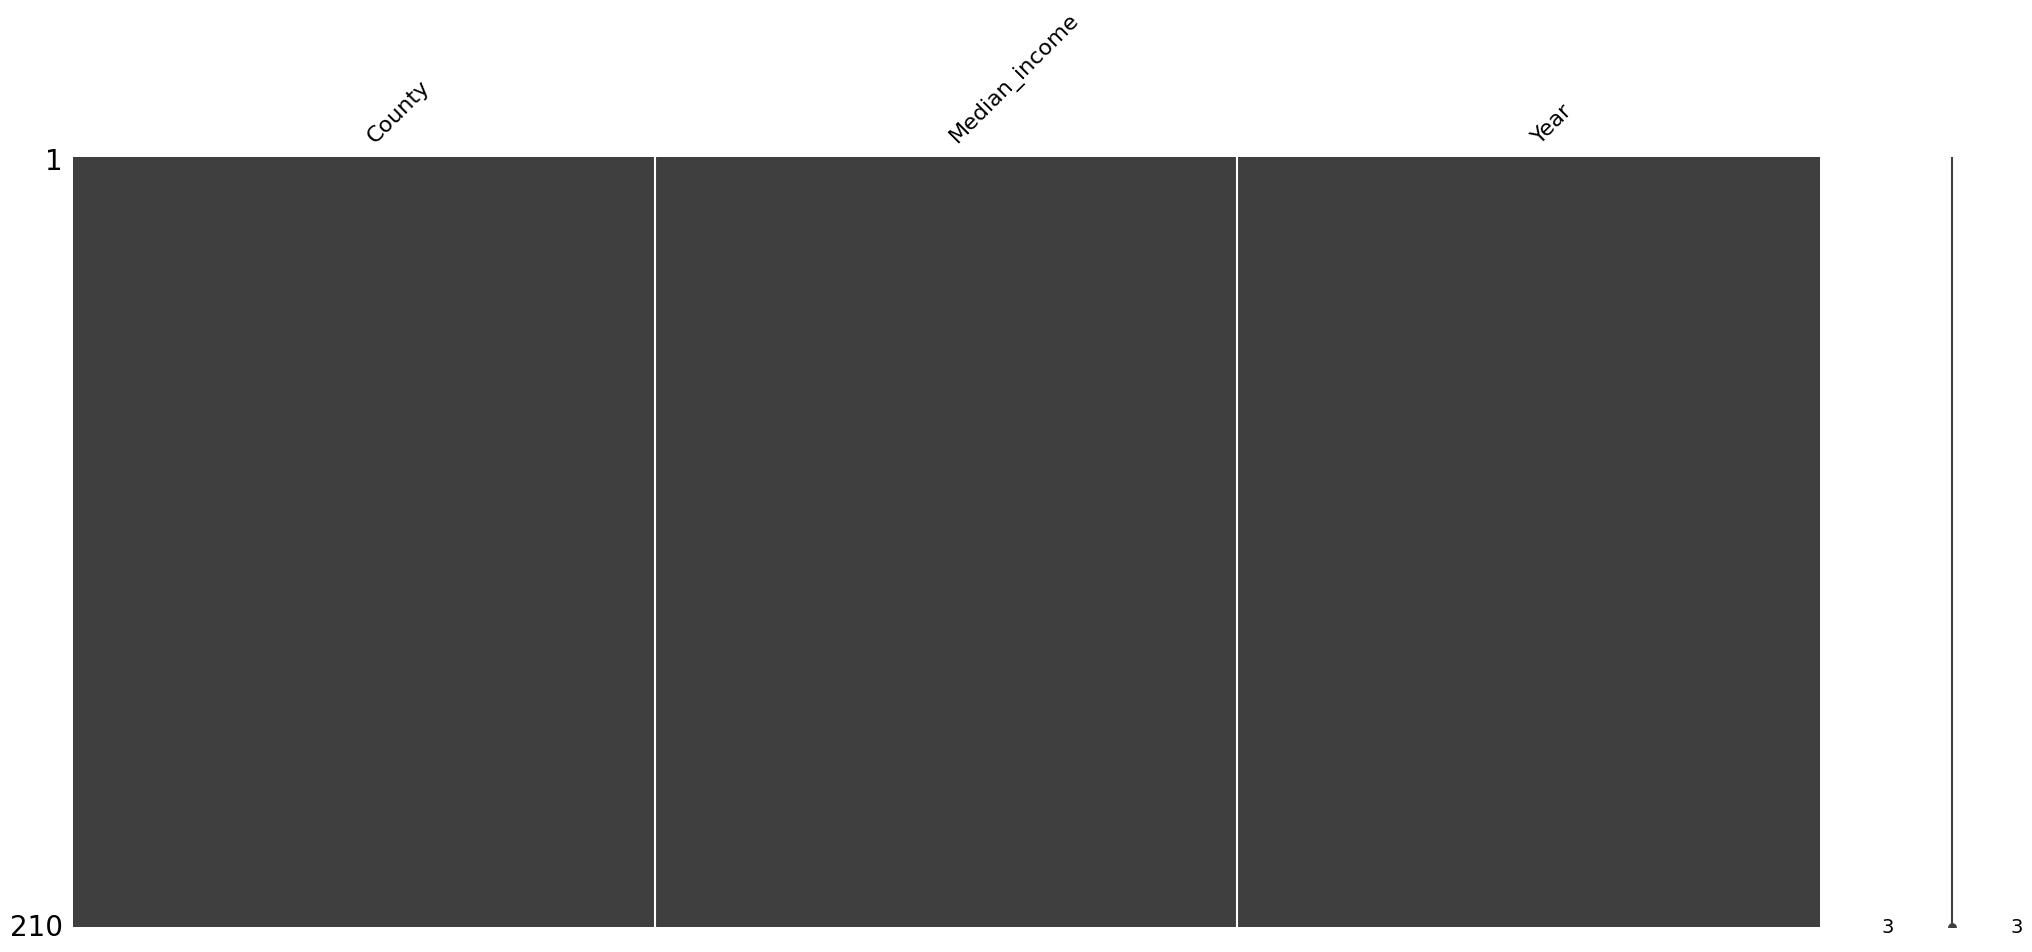

In [110]:
msno.matrix(acsinc)

In [118]:
acs_popinc= pd.merge(acspop, acsinc, how="outer", on=['County', 'Year'], indicator=True)
acs_popinc.head(3)

,County,Totalpop,H_units,Year,Median_income,_merge
0,Atlantic,274685,126723,2010,52571,both
1,Atlantic,275422,127361,2012,51191,both
2,Atlantic,275209,127386,2014,55313,both


In [119]:
acs_popinc['_merge'].value_counts()

,count
_merge,
both,210
left_only,0
right_only,0


In [121]:
acs_popinc = acs_popinc.drop(columns=["_merge"])
acs_popinc.head(3)

,County,Totalpop,H_units,Year,Median_income
0,Atlantic,274685,126723,2010,52571
1,Atlantic,275422,127361,2012,51191
2,Atlantic,275209,127386,2014,55313


#Zillow Data
Zillow home value index (ZHVI) and observed rent index (ZORI) for the 35th to 65th percentile range for homes in each county.

**Variables of interest:** end-of-year average home value, end-of-year average rent.

**Timeframe available:** monthly from 2000 through September 2026.

**Areas in dataset:** Counties in all of USA.

**Source:** [Zillow Housing Data](https://www.zillow.com/research/data/)

In [122]:
! wget -q -O county_zhvi_homevalue.csv https://raw.githubusercontent.com/carlavilla/DataManagement/main/county_zhvi_homevalue.csv
homeval=pd.read_csv('county_zhvi_homevalue.csv')
homeval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3071 entries, 0 to 3070
Columns: 330 entries, RegionID to 2026-09-30
dtypes: float64(321), int64(4), object(5)
memory usage: 7.7+ MB
